# Do Language Model Representations Encode Reading Age?
### A Probing & Steering Study on Children's Story Corpora

---

## Motivation & Research Questions

Children's stories are written for specific developmental age ranges — vocabulary, sentence length, syntactic complexity, and narrative structure all shift systematically as target age increases. This creates a natural test bed for mechanistic interpretability: **does a language model internally represent these register differences, or does it treat all story text the same?**

We investigate three nested questions:

1. **Probing:** Can a *thin* linear classifier trained on frozen BERT hidden states predict which age range a story chunk belongs to? At which layer is the signal strongest?
2. **Transfer Asymmetry:** If we fine-tune on only the *youngest* story and test on the *oldest* — vs. the reverse — does direction matter? A register hierarchy predicts that older → younger should transfer better.
3. **Steering:** Can we take a mean-difference vector from young-vs-old story activations and *causally intervene* on the model's hidden states to shift its generation register?

---

## Methodology Rationale

### Why linear probing?
A linear probe (logistic regression on frozen embeddings) asks *what information is geometrically accessible* in a representation. If a non-linear classifier is needed, the feature is encoded but entangled; if even a linear probe fails, the feature simply isn't present. We probe **every layer** to produce a layer-wise accuracy curve — this tells us *where* in the network the representation crystallises. We also run a **shuffled-label control** to confirm the probe exploits real age signal rather than incidental correlates (e.g., story length).

### Why mean-difference steering?
Probing is correlational. Activation steering (adding $v = \hat{\mu}_{old} - \hat{\mu}_{young}$, scaled by $\alpha$, into a layer's residual stream) provides a **causal test**: if the steered model generates more complex vocabulary, the representation isn't just passively storing age — it actively drives generation. We sweep both layer and $\alpha$ to find the most effective intervention point.

### Why Gaussian soft labels?
Age ranges like '2–5 years' are inherently fuzzy. Encoding each story's label as $\mathcal{N}(\mu, \sigma^2)$ and training with KL-divergence loss prevents overconfidence at boundaries, produces better-calibrated classifiers, and propagates gradients proportional to developmental proximity.

### Why measure transfer asymmetry?
If register is strictly nested (all vocabulary used for young readers also appears in older texts), a model trained on older stories should transfer to younger ones better than the reverse. The **asymmetry score** $\Delta = \text{Acc}_{old \to young} - \text{Acc}_{young \to old}$ directly quantifies this.

---
**Setup:** Place story `.txt` files in `stories/` as `005047.txt`, `010380.txt`, `005049.txt`. Update `AGE_RANGES` after the xlsx lookup in Step 0.

In [ ]:
!pip install transformers datasets torch scikit-learn umap-learn matplotlib seaborn openpyxl -q

In [ ]:
import os, re, warnings, random
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy.stats import norm

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    DistilBertTokenizerFast, DistilBertModel,
    AutoTokenizer, AutoModelForCausalLM, AutoConfig,
    get_linear_schedule_with_warmup,
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
import umap

warnings.filterwarnings('ignore')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SEED   = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

PALETTE = ['#4e9af1', '#f4a261', '#2a9d8f']
sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})
print(f'Device: {DEVICE}')

Device: cuda


## Step 0 — Configuration & Age-Range Loading

In [ ]:
# ── UPDATE THESE after xlsx lookup ───────────────────────────────────────────
AGE_RANGES = {
    # youngest group (5 stories)
    '010401': (2, 5),
    '010739': (2, 5),
    '017285': (2, 5),
    '017290': (2, 5),
    '017310': (2, 5),

    # middle group (5 stories)
    '010386': (4, 8),
    '010391': (4, 8),
    '010399': (4, 8),
    '010684': (4, 8),
    '010690': (4, 8),

    # oldest group (5 stories)
    '010392': (7, 10),
    '010393': (7, 10),
    '010693': (6, 9),
    '010731': (7, 12),
    '010738': (6, 10),
}
STORIES_DIR    = Path('stories')
BERT_MODEL     = 'distilbert-base-uncased'
GPT2_MODEL     = 'gpt2'             # use 'gpt2-large' on A100
MAX_LEN        = 128
CHUNK_STRIDE   = 64
BATCH_SIZE     = 16
FINETUNE_EPOCHS = 4
LR             = 2e-5

In [ ]:
def parse_age_range(s):
    m = re.search(r'(\d+)\s*[-–]\s*(\d+)', str(s))
    return (float(m.group(1)), float(m.group(2))) if m else None

def load_age_ranges_from_xlsx(xlsx_path, story_ids):
    df = pd.read_excel(xlsx_path, dtype=str)
    df.columns = [c.strip().lower().replace(' ', '_') for c in df.columns]
    print('Columns:', df.columns.tolist())
    id_col  = next((c for c in df.columns if 'story' in c and 'id' in c), None)
    age_col = next((c for c in df.columns if 'reading' in c and 'age' in c), None)
    if not id_col or not age_col:
        print('Auto-detect failed. Set id_col/age_col manually.'); return {}
    out = {}
    for sid in story_ids:
        row = df[df[id_col].str.zfill(6) == str(sid).zfill(6)]
        if not row.empty:
            parsed = parse_age_range(row.iloc[0][age_col])
            if parsed:
                out[sid] = parsed
                print(f'  {sid}: {row.iloc[0][age_col]} → {parsed}')
    return out

# Uncomment to load real values:
# loaded = load_age_ranges_from_xlsx('data/all_story_nosub_manual_amazon.xlsx', list(AGE_RANGES))
# AGE_RANGES.update(loaded)

story_ids_sorted = sorted(AGE_RANGES, key=lambda k: AGE_RANGES[k][0])
age_bins  = [AGE_RANGES[sid] for sid in story_ids_sorted]
n_classes = len(age_bins)
print('Order (youngest→oldest):', story_ids_sorted)

Order (youngest→oldest): ['010401', '010739', '017285', '017290', '017310', '010386', '010391', '010399', '010684', '010690', '010693', '010738', '010392', '010393', '010731']


## Step 1 — Gaussian Age Encoding

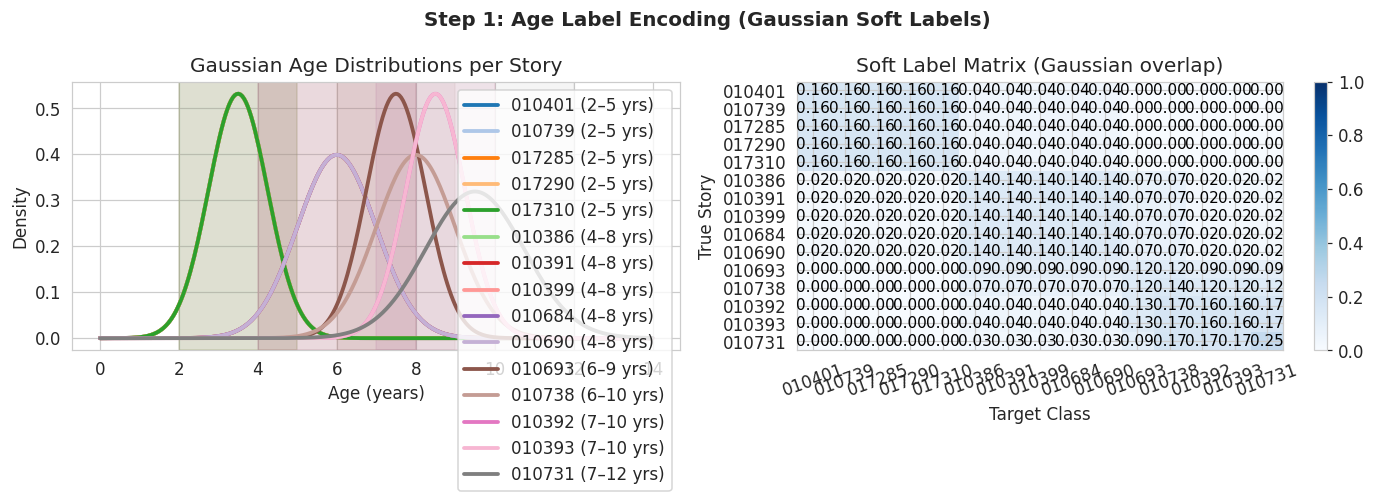

In [ ]:
def age_to_gaussian(lo, hi): return (lo + hi) / 2, (hi - lo) / 4

def gaussian_soft_label(mu, sigma, bins):
    probs = np.array([norm.cdf(h, mu, sigma) - norm.cdf(l, mu, sigma) for l, h in bins])
    return probs / probs.sum()

soft_matrix = np.array([
    gaussian_soft_label(*age_to_gaussian(*AGE_RANGES[sid]), age_bins)
    for sid in story_ids_sorted
])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
x = np.linspace(0, 14, 300)
# Generate enough distinct colors for all n_classes
new_palette = [plt.cm.get_cmap('tab20')(j) for j in range(n_classes)]
for i, sid in enumerate(story_ids_sorted):
    lo, hi = AGE_RANGES[sid]
    mu, sg = age_to_gaussian(lo, hi)
    ax.plot(x, norm.pdf(x, mu, sg), color=new_palette[i], lw=2.5, label=f'{sid} ({lo}–{hi} yrs)')
    ax.axvspan(lo, hi, alpha=0.07, color=new_palette[i])
ax.set_xlabel('Age (years)'); ax.set_ylabel('Density')
ax.set_title('Gaussian Age Distributions per Story'); ax.legend()

ax2 = axes[1]
im = ax2.imshow(soft_matrix, cmap='Blues', vmin=0, vmax=1, aspect='auto')
ax2.set_xticks(range(n_classes)); ax2.set_xticklabels(story_ids_sorted, rotation=20)
ax2.set_yticks(range(n_classes)); ax2.set_yticklabels(story_ids_sorted)
ax2.set_xlabel('Target Class'); ax2.set_ylabel('True Story')
ax2.set_title('Soft Label Matrix (Gaussian overlap)')
for i in range(n_classes):
    for j in range(n_classes):
        ax2.text(j, i, f'{soft_matrix[i,j]:.2f}', ha='center', va='center',
                 color='white' if soft_matrix[i,j] > 0.6 else 'black', fontsize=10)
plt.colorbar(im, ax=ax2)
plt.suptitle('Step 1: Age Label Encoding (Gaussian Soft Labels)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

In [ ]:
!pip install textstat -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.1/177.1 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 91.0 MB/s eta 0:00:00


In [ ]:
import textstat
import re
from collections import Counter

# Common English pronouns for counting
PRONOUNS = set(["i", "me", "my", "mine", "myself", "you", "your", "yours", "yourself",
                "he", "him", "his", "himself", "she", "her", "hers", "herself",
                "it", "its", "itself", "we", "us", "our", "ours", "ourselves",
                "they", "them", "their", "theirs", "themselves", "who", "whom",
                "whose", "which", "what", "that", "this", "these", "those",
                "all", "any", "anyone", "anything", "each", "every", "everyone",
                "everything", "few", "many", "nobody", "none", "one", "several",
                "some", "somebody", "someone", "something"]) # Simplified list

def calculate_linguistic_features(text):
    sentences = re.split(r'[.!?]\s*', text)
    sentences = [s for s in sentences if s.strip()] # Remove empty sentences

    words = re.findall(r'\b\w+\b', text.lower())

    num_sentences = len(sentences)
    total_words   = len(words)

    mean_sentence_length_words = np.mean([len(re.findall(r'\b\w+\b', s)) for s in sentences]) if num_sentences > 0 else 0
    mean_word_length_chars = np.mean([len(w) for w in words]) if total_words > 0 else 0

    num_pronouns = sum(1 for word in words if word in PRONOUNS)

    # Flesch Reading Ease - handle potential errors for very short texts
    try:
        flesch_re = textstat.flesch_reading_ease(text)
    except Exception:
        flesch_re = np.nan # Assign NaN if calculation fails

    return {
        'num_sentences': num_sentences,
        'mean_sentence_length_words': mean_sentence_length_words,
        'mean_word_length_chars': mean_word_length_chars,
        'num_pronouns': num_pronouns,
        'flesch_reading_ease': flesch_re
    }

print('Calculating linguistic features for each chunk...')
features_df = df['text'].apply(calculate_linguistic_features).apply(pd.Series)
df = pd.concat([df, features_df], axis=1)

print('Features calculated. Displaying first 5 rows with new features:')
display(df.head())

Calculating linguistic features for each chunk...
Features calculated. Displaying first 5 rows with new features:


,text,story_id,class_idx,num_sentences,mean_sentence_length_words,mean_word_length_chars,num_pronouns,flesch_reading_ease
0,A lot of people thought Old Sam was crazy. Old...,010401,0,8.0,12.625000,3.851485,10.0,84.635341
1,Sometimes he was friendly and smiled at people...,010401,0,7.0,12.428571,4.310345,9.0,77.810714
2,"""What's Old Sam going to do with those?"" peopl...",010401,0,8.0,12.625000,4.495050,10.0,75.708333
3,Sometimes he paid the neighborhood kids pennie...,010401,0,9.0,9.666667,4.218391,13.0,83.853571
4,People could hear him working in his backyard ...,010401,0,11.0,9.181818,4.089109,12.0,84.258442


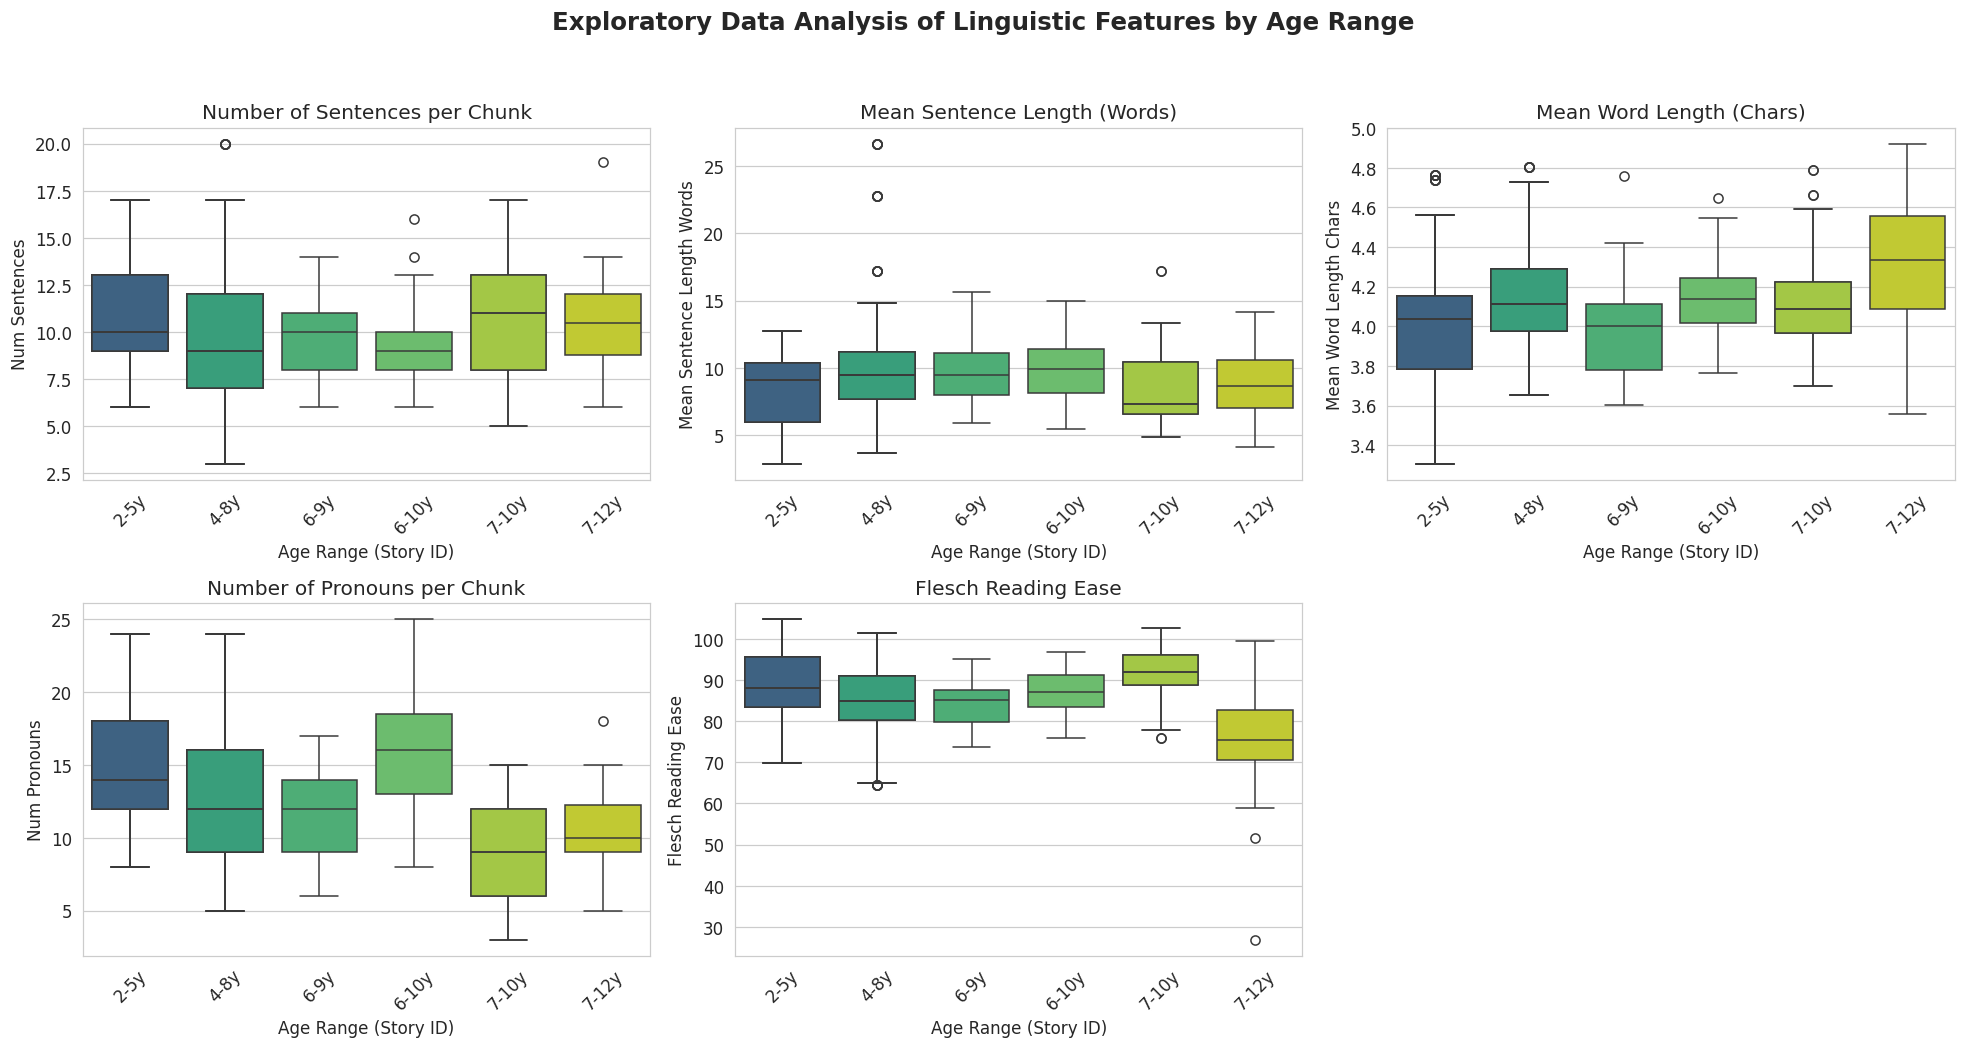

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

feature_cols = ['num_sentences', 'mean_sentence_length_words', 'mean_word_length_chars', 'num_pronouns', 'flesch_reading_ease']
titles = ['Number of Sentences per Chunk', 'Mean Sentence Length (Words)', 'Mean Word Length (Chars)', 'Number of Pronouns per Chunk', 'Flesch Reading Ease']

# Map class_idx to age ranges for better labels
age_range_labels = {idx: f'{AGE_RANGES[sid][0]}-{AGE_RANGES[sid][1]}y' for idx, sid in enumerate(story_ids_sorted)}
df['age_label'] = df['class_idx'].map(age_range_labels)

for i, (col, title) in enumerate(zip(feature_cols, titles)):
    if col == 'num_sentences' or col == 'num_pronouns':
        sns.boxplot(x='age_label', y=col, data=df, ax=axes[i], palette='viridis', order=[age_range_labels[idx] for idx in sorted(age_range_labels.keys())])
    else:
        sns.boxplot(x='age_label', y=col, data=df, ax=axes[i], palette='viridis', order=[age_range_labels[idx] for idx in sorted(age_range_labels.keys())])
    axes[i].set_title(title)
    axes[i].set_xlabel('Age Range (Story ID)')
    axes[i].set_ylabel(col.replace('_', ' ').title())
    axes[i].tick_params(axis='x', rotation=45)

# Hide any unused subplots
for i in range(len(feature_cols), len(axes)):
    fig.delaxes(axes[i])

plt.suptitle('Exploratory Data Analysis of Linguistic Features by Age Range', fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## Step 2 — Load & Chunk Stories

In [ ]:
bert_tokenizer = DistilBertTokenizerFast.from_pretrained(BERT_MODEL)

def load_and_chunk(txt_path, story_id, tokenizer, max_len=MAX_LEN, stride=CHUNK_STRIDE):
    text = Path(txt_path).read_text(encoding='utf-8', errors='replace').strip()
    sentences = re.split(r'(?<=[.!?])\s+', text)
    chunks, buf, buf_tok = [], [], 0
    for sent in sentences:
        t = len(tokenizer(sent, add_special_tokens=False)['input_ids'])
        if buf_tok + t > max_len - 2 and buf:
            chunks.append(' '.join(buf))
            while buf and buf_tok > stride:
                buf_tok -= len(tokenizer(buf.pop(0), add_special_tokens=False)['input_ids'])
        buf.append(sent); buf_tok += t
    if buf: chunks.append(' '.join(buf))
    cidx = story_ids_sorted.index(story_id)
    return [{'text': c, 'story_id': story_id, 'class_idx': cidx} for c in chunks]

STORIES_DIR.mkdir(exist_ok=True)
all_chunks = []
for sid in story_ids_sorted:
    p = STORIES_DIR / f'{sid}.txt'
    chunks = load_and_chunk(p, sid, bert_tokenizer)
    all_chunks.extend(chunks)
    print(f'  {sid} ({AGE_RANGES[sid][0]}–{AGE_RANGES[sid][1]}y): {len(chunks)} chunks')

df = pd.DataFrame(all_chunks)
all_labels = df['class_idx'].values
print(f'\nTotal: {len(df)} chunks')

  010401 (2–5y): 10 chunks
  010739 (2–5y): 11 chunks
  017285 (2–5y): 6 chunks
  017290 (2–5y): 17 chunks
  017310 (2–5y): 5 chunks
  010386 (4–8y): 8 chunks
  010391 (4–8y): 13 chunks
  010399 (4–8y): 13 chunks
  010684 (4–8y): 15 chunks
  010690 (4–8y): 20 chunks
  010693 (6–9y): 25 chunks
  010738 (6–10y): 39 chunks
  010392 (7–10y): 15 chunks
  010393 (7–10y): 18 chunks
  010731 (7–12y): 40 chunks

Total: 255 chunks


## Experiment 1 — Layer-Wise Linear Probing

**Rationale:** We extract mean-pooled hidden states from *every* DistilBERT layer without fine-tuning, then train a logistic regression probe on each. The resulting accuracy curve answers: *at which depth does the model's geometry best separate age groups?*

- **Early layers** encode surface/lexical features (word length, frequency, morphology)
- **Later layers** encode syntactic and semantic abstractions

A probe peaking at an early layer suggests the age signal is primarily **lexical** (vocabulary choice). A late-peaking probe implicates **syntactic complexity**. The **shuffled-label control** isolates real age signal from incidental correlates such as average chunk length.

In [ ]:
@torch.no_grad()
def extract_all_layers(texts, tokenizer, model_name=BERT_MODEL, batch=32):
    """
    Extract mean-pooled hidden states from every DistilBERT layer.
    Returns list of (N, hidden_size) arrays, one per layer.
    """
    bert = DistilBertModel.from_pretrained(model_name, output_hidden_states=True).to(DEVICE)
    bert.eval()
    n_layers = bert.config.num_hidden_layers + 1  # embedding + transformer layers
    buckets  = [[] for _ in range(n_layers)]
    for i in range(0, len(texts), batch):
        enc = tokenizer(texts[i:i+batch], return_tensors='pt',
                        padding=True, truncation=True, max_length=MAX_LEN).to(DEVICE)
        out  = bert(**enc)
        mask = enc['attention_mask'].unsqueeze(-1).float()
        for li, hs in enumerate(out.hidden_states):
            pooled = (hs * mask).sum(1) / mask.sum(1)
            buckets[li].append(pooled.cpu().numpy())
    del bert; torch.cuda.empty_cache()
    return [np.vstack(b) for b in buckets]

print('Extracting per-layer embeddings (pretrained, frozen)...')
layer_embs = extract_all_layers(df['text'].tolist(), bert_tokenizer)
print(f'Extracted {len(layer_embs)} layers × {layer_embs[0].shape[0]} samples × {layer_embs[0].shape[1]}d')

Extracting per-layer embeddings (pretrained, frozen)...


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Extracted 7 layers × 255 samples × 768d


In [ ]:
def probe_layer(X, y, shuffle=False, seed=SEED):
    y_use = y.copy()
    if shuffle:
        np.random.default_rng(seed).shuffle(y_use)
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y_use, test_size=0.25, stratify=df['story_id'], random_state=seed)
    sc = StandardScaler()
    clf = LogisticRegression(max_iter=500, C=1.0, random_state=seed)
    clf.fit(sc.fit_transform(X_tr), y_tr)
    return clf.score(sc.transform(X_te), y_te), clf

probe_accs, control_accs, probe_clfs = [], [], []
for li, embs in enumerate(layer_embs):
    acc, clf = probe_layer(embs, all_labels)
    ctrl, _  = probe_layer(embs, all_labels, shuffle=True)
    probe_accs.append(acc)
    control_accs.append(ctrl)
    probe_clfs.append(clf)
    tag = 'Embed' if li == 0 else f'L{li}'
    print(f'  {tag:6s}  probe={acc:.3f}  control={ctrl:.3f}  Δ={acc-ctrl:+.3f}')

best_layer = int(np.argmax(probe_accs))
print(f'\n→ Best probe layer: {best_layer}  (acc={probe_accs[best_layer]:.3f})')

  Embed   probe=0.984  control=0.125  Δ=+0.859
  L1      probe=0.969  control=0.172  Δ=+0.797
  L2      probe=0.969  control=0.141  Δ=+0.828
  L3      probe=0.953  control=0.141  Δ=+0.812
  L4      probe=0.938  control=0.125  Δ=+0.812
  L5      probe=0.953  control=0.062  Δ=+0.891
  L6      probe=0.969  control=0.109  Δ=+0.859

→ Best probe layer: 0  (acc=0.984)


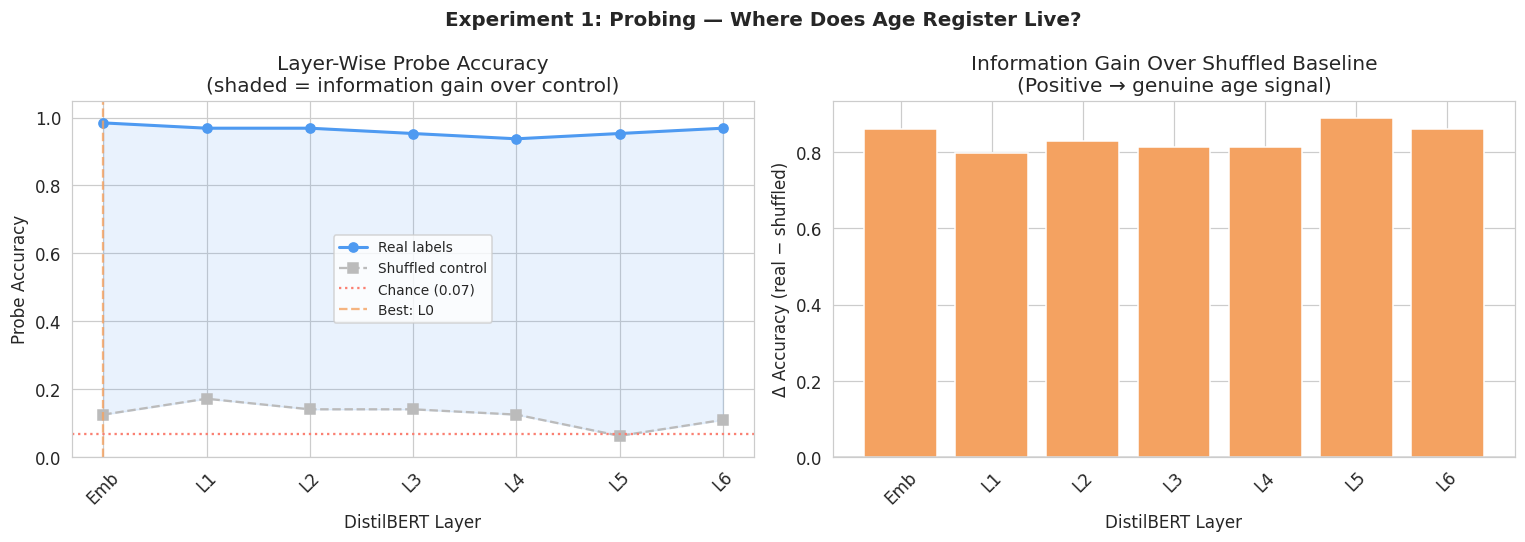

In [ ]:
layer_names = ['Emb'] + [f'L{i}' for i in range(1, len(probe_accs))]
delta_probe = np.array(probe_accs) - np.array(control_accs)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: accuracy curve
ax = axes[0]
ax.plot(probe_accs,    marker='o', lw=2,   color='#4e9af1', label='Real labels')
ax.plot(control_accs, marker='s', lw=1.5, color='#bbb',    ls='--', label='Shuffled control')
ax.axhline(1/n_classes, color='salmon', ls=':', label=f'Chance ({1/n_classes:.2f})')
ax.axvline(best_layer, color='#f4a261',  ls='--', alpha=0.8, label=f'Best: L{best_layer}')
ax.fill_between(range(len(probe_accs)), probe_accs, control_accs, alpha=0.12, color='#4e9af1')
ax.set_xticks(range(len(probe_accs))); ax.set_xticklabels(layer_names, rotation=45)
ax.set_ylim(0, 1.05); ax.set_xlabel('DistilBERT Layer'); ax.set_ylabel('Probe Accuracy')
ax.set_title('Layer-Wise Probe Accuracy\n(shaded = information gain over control)')
ax.legend(fontsize=9)

# Right: information gain bars
ax2 = axes[1]
colors_bar = [PALETTE[1] if d > 0 else '#ddd' for d in delta_probe]
ax2.bar(layer_names, delta_probe, color=colors_bar, edgecolor='white')
ax2.axhline(0, color='black', lw=0.8)
ax2.set_xticks(range(len(delta_probe))); ax2.set_xticklabels(layer_names, rotation=45)
ax2.set_xlabel('DistilBERT Layer')
ax2.set_ylabel('Δ Accuracy (real − shuffled)')
ax2.set_title('Information Gain Over Shuffled Baseline\n(Positive → genuine age signal)')

plt.suptitle('Experiment 1: Probing — Where Does Age Register Live?',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

### Experiment 1b — Probing for Confounders: Sentence Length & Vocabulary Level

To investigate whether simpler linguistic features like sentence length and vocabulary level (proxied by Flesch Reading Ease) might act as strong confounders or correlates of the age signal, we perform additional layer-wise linear probes. We categorize these continuous features into discrete bins (e.g., 'low', 'medium', 'high') and train separate probes for each. This reveals how strongly these individual features are encoded within DistilBERT's layers.

In [ ]:
# Create binned labels for Sentence Length
df['sent_len_bin'] = pd.qcut(df['mean_sentence_length_words'], q=3, labels=['low', 'medium', 'high'], duplicates='drop')
sent_len_labels = df['sent_len_bin'].cat.codes.values

# Create binned labels for Flesch Reading Ease (vocabulary level)
df['flesch_re_bin'] = pd.qcut(df['flesch_reading_ease'], q=3, labels=['low', 'medium', 'high'], duplicates='drop')
flesch_re_labels = df['flesch_re_bin'].cat.codes.values

print("Binned labels created for sentence length and Flesch Reading Ease.")
display(df[['mean_sentence_length_words', 'sent_len_bin', 'flesch_reading_ease', 'flesch_re_bin']].head())

Binned labels created for sentence length and Flesch Reading Ease.


,mean_sentence_length_words,sent_len_bin,flesch_reading_ease,flesch_re_bin
0,12.625000,high,84.635341,medium
1,12.428571,high,77.810714,low
2,12.625000,high,75.708333,low
3,9.666667,medium,83.853571,medium
4,9.181818,medium,84.258442,medium


In [ ]:
print('Probing for Sentence Length Bins...')
sent_len_probe_accs, sent_len_control_accs = [], []
for li, embs in enumerate(layer_embs):
    acc, _ = probe_layer(embs, sent_len_labels)
    ctrl, _  = probe_layer(embs, sent_len_labels, shuffle=True)
    sent_len_probe_accs.append(acc)
    sent_len_control_accs.append(ctrl)
    tag = 'Emb' if li == 0 else f'L{li}'
    print(f'  {tag:6s}  probe={acc:.3f}  control={ctrl:.3f}  Δ={acc-ctrl:+.3f}')

print('\nProbing for Flesch Reading Ease Bins...')
flesch_re_probe_accs, flesch_re_control_accs = [], []
for li, embs in enumerate(layer_embs):
    acc, _ = probe_layer(embs, flesch_re_labels)
    ctrl, _  = probe_layer(embs, flesch_re_labels, shuffle=True)
    flesch_re_probe_accs.append(acc)
    flesch_re_control_accs.append(ctrl)
    tag = 'Emb' if li == 0 else f'L{li}'
    print(f'  {tag:6s}  probe={acc:.3f}  control={ctrl:.3f}  Δ={acc-ctrl:+.3f}')

Probing for Sentence Length Bins...
  Emb     probe=0.688  control=0.281  Δ=+0.406
  L1      probe=0.750  control=0.375  Δ=+0.375
  L2      probe=0.656  control=0.375  Δ=+0.281
  L3      probe=0.703  control=0.391  Δ=+0.312
  L4      probe=0.703  control=0.281  Δ=+0.422
  L5      probe=0.734  control=0.266  Δ=+0.469
  L6      probe=0.750  control=0.297  Δ=+0.453

Probing for Flesch Reading Ease Bins...
  Emb     probe=0.656  control=0.375  Δ=+0.281
  L1      probe=0.609  control=0.297  Δ=+0.312
  L2      probe=0.656  control=0.297  Δ=+0.359
  L3      probe=0.656  control=0.281  Δ=+0.375
  L4      probe=0.656  control=0.344  Δ=+0.312
  L5      probe=0.656  control=0.438  Δ=+0.219
  L6      probe=0.625  control=0.359  Δ=+0.266


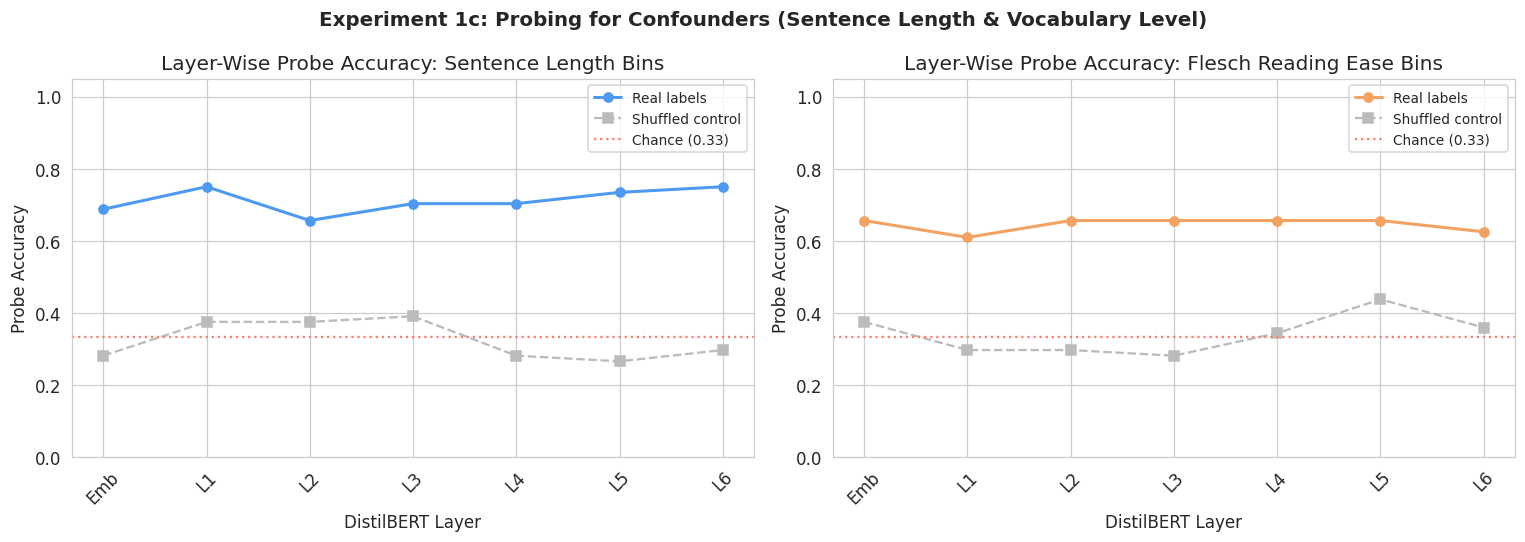

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot for Sentence Length Probe
ax1 = axes[0]
ax1.plot(sent_len_probe_accs, marker='o', lw=2, color=PALETTE[0], label='Real labels')
ax1.plot(sent_len_control_accs, marker='s', lw=1.5, color='#bbb', ls='--', label='Shuffled control')
ax1.axhline(1/len(np.unique(sent_len_labels)), color='salmon', ls=':', label=f'Chance ({1/len(np.unique(sent_len_labels)):.2f})')
ax1.set_xticks(range(len(layer_embs)))
ax1.set_xticklabels(layer_names, rotation=45)
ax1.set_ylim(0, 1.05); ax1.set_xlabel('DistilBERT Layer'); ax1.set_ylabel('Probe Accuracy')
ax1.set_title('Layer-Wise Probe Accuracy: Sentence Length Bins')
ax1.legend(fontsize=9)

# Plot for Flesch Reading Ease Probe
ax2 = axes[1]
ax2.plot(flesch_re_probe_accs, marker='o', lw=2, color=PALETTE[1], label='Real labels')
ax2.plot(flesch_re_control_accs, marker='s', lw=1.5, color='#bbb', ls='--', label='Shuffled control')
ax2.axhline(1/len(np.unique(flesch_re_labels)), color='salmon', ls=':', label=f'Chance ({1/len(np.unique(flesch_re_labels)):.2f})')
ax2.set_xticks(range(len(layer_embs)))
ax2.set_xticklabels(layer_names, rotation=45)
ax2.set_ylim(0, 1.05); ax2.set_xlabel('DistilBERT Layer'); ax2.set_ylabel('Probe Accuracy')
ax2.set_title('Layer-Wise Probe Accuracy: Flesch Reading Ease Bins')
ax2.legend(fontsize=9)

plt.suptitle('Experiment 1c: Probing for Confounders (Sentence Length & Vocabulary Level)',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

## Experiment 1b — Representation Geometry (UMAP)

We visualise the best-layer embeddings using UMAP to ask: do age groups form **geometrically separable clusters** in the frozen representation space?
We compare Layer 0 (pure token embedding) vs. the best probe layer to show how representations evolve with depth.

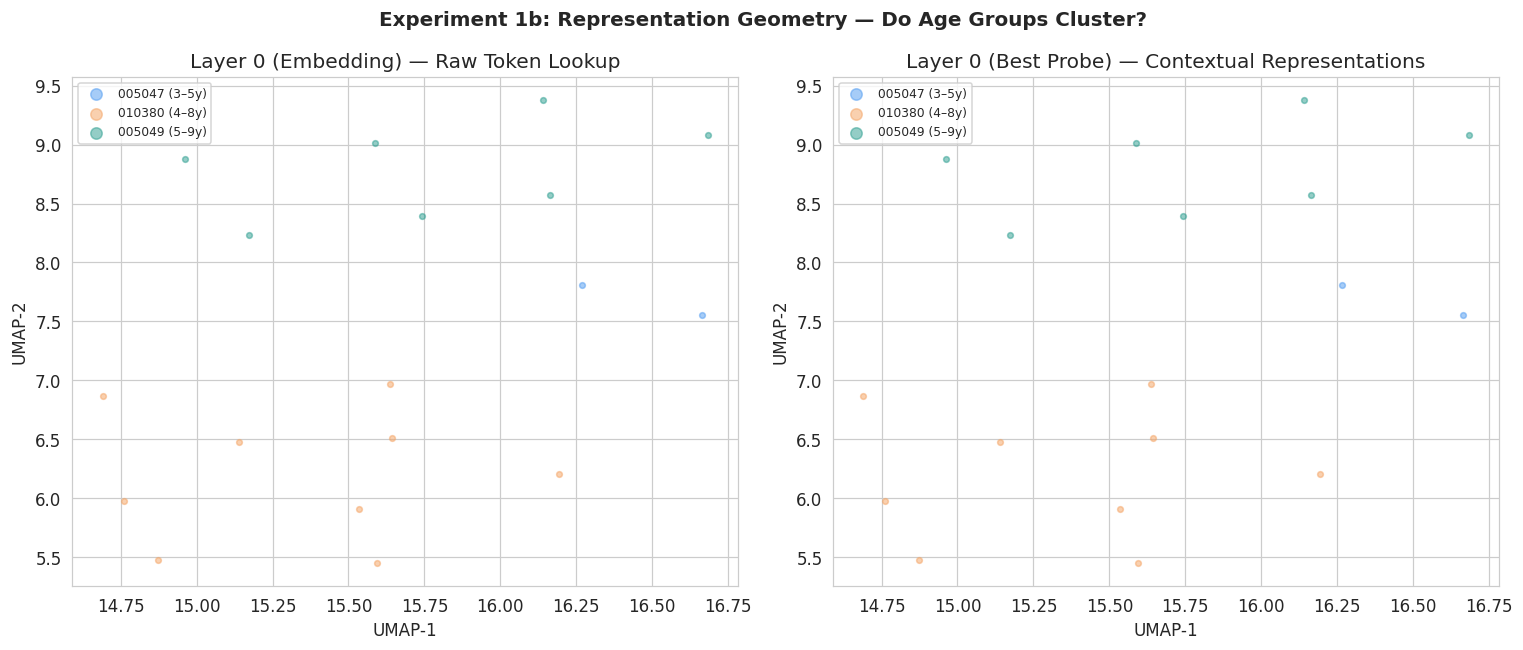

In [ ]:
def plot_umap_panel(ax, embs, labels, title):
    reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED, metric='cosine')
    proj = reducer.fit_transform(embs)
    for i, sid in enumerate(story_ids_sorted):
        mask = labels == i
        lo, hi = AGE_RANGES[sid]
        ax.scatter(proj[mask, 0], proj[mask, 1], c=PALETTE[i], alpha=0.5, s=14,
                   label=f'{sid} ({lo}–{hi}y)')
    ax.set_title(title); ax.legend(markerscale=2, fontsize=8)
    ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
    return proj

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_umap_panel(axes[0], layer_embs[0],          all_labels,
                'Layer 0 (Embedding) — Raw Token Lookup')
plot_umap_panel(axes[1], layer_embs[best_layer], all_labels,
                f'Layer {best_layer} (Best Probe) — Contextual Representations')
plt.suptitle('Experiment 1b: Representation Geometry — Do Age Groups Cluster?',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

## Experiment 2 — Fine-Tuned Soft-Label Classifier

**Rationale:** Probing uses a *frozen* backbone. Here we ask how much fine-tuning improves separation. We use **KL-divergence loss against Gaussian soft labels** rather than cross-entropy against hard labels because:
- A 5-year-old story is not categorically different from a 6-year-old one
- Soft labels propagate gradients proportional to developmental proximity
- The classifier weights can later be inspected for what features drove the separation

After training, we compare UMAP geometry *before* and *after* fine-tuning.

In [ ]:
def build_labels(sub_df):
    hard = sub_df['class_idx'].values
    soft = np.array([
        gaussian_soft_label(*age_to_gaussian(*AGE_RANGES[sid]), age_bins)
        for sid in sub_df['story_id']
    ])
    return hard, soft

class StoryDataset(Dataset):
    def __init__(self, sub_df, tokenizer):
        self.texts = sub_df['text'].tolist()
        self.hard, self.soft = build_labels(sub_df)
        self.tok = tokenizer
    def __len__(self): return len(self.texts)
    def __getitem__(self, i):
        enc = self.tok(self.texts[i], max_length=MAX_LEN, padding='max_length',
                       truncation=True, return_tensors='pt')
        return {
            'input_ids':      enc['input_ids'].squeeze(),
            'attention_mask': enc['attention_mask'].squeeze(),
            'label_hard': torch.tensor(self.hard[i], dtype=torch.long),
            'label_soft': torch.tensor(self.soft[i], dtype=torch.float),
        }

class SoftLabelDistilBERT(nn.Module):
    def __init__(self, n_cls, dropout=0.2):
        super().__init__()
        self.bert = DistilBertModel.from_pretrained(BERT_MODEL)
        self.drop = nn.Dropout(dropout)
        self.clf  = nn.Linear(self.bert.config.hidden_size, n_cls)
    def forward(self, input_ids, attention_mask, labels_soft=None):
        cls  = self.bert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0]
        logits   = self.clf(self.drop(cls))
        log_prob = torch.log_softmax(logits, dim=-1)
        loss = nn.KLDivLoss(reduction='batchmean')(log_prob, labels_soft) if labels_soft is not None else None
        return {'loss': loss, 'logits': logits, 'cls_emb': cls}

def run_epoch(model, loader, optimizer=None, scheduler=None):
    model.train() if optimizer else model.eval()
    tot_loss, preds, trues, embs = 0, [], [], []
    ctx = torch.enable_grad() if optimizer else torch.no_grad()
    with ctx:
        for b in loader:
            ids  = b['input_ids'].to(DEVICE)
            mask = b['attention_mask'].to(DEVICE)
            soft = b['label_soft'].to(DEVICE)
            hard = b['label_hard'].to(DEVICE)
            out  = model(ids, mask, labels_soft=soft)
            if optimizer:
                out['loss'].backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step(); scheduler.step(); optimizer.zero_grad()
            tot_loss += out['loss'].item()
            preds.extend(out['logits'].argmax(1).cpu().tolist())
            trues.extend(hard.cpu().tolist())
            embs.append(out['cls_emb'].detach().cpu().numpy())
    return tot_loss/len(loader), np.array(preds), np.array(trues), np.vstack(embs)

train_df, val_df = train_test_split(df, test_size=0.25, stratify=df['story_id'], random_state=SEED)
train_loader = DataLoader(StoryDataset(train_df, bert_tokenizer), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(StoryDataset(val_df,   bert_tokenizer), batch_size=BATCH_SIZE)

ft_model   = SoftLabelDistilBERT(n_classes).to(DEVICE)
optimizer  = torch.optim.AdamW(ft_model.parameters(), lr=LR, weight_decay=0.01)
total_steps = len(train_loader) * FINETUNE_EPOCHS
scheduler   = get_linear_schedule_with_warmup(optimizer, total_steps//10, total_steps)

history = defaultdict(list)
for ep in range(1, FINETUNE_EPOCHS+1):
    tl, tp, tt, _ = run_epoch(ft_model, train_loader, optimizer, scheduler)
    vl, vp, vt, _ = run_epoch(ft_model, val_loader)
    history['train_loss'].append(tl); history['val_loss'].append(vl)
    history['train_acc'].append((tp==tt).mean()); history['val_acc'].append((vp==vt).mean())
    print(f'Ep {ep}  train={tl:.4f}/{(tp==tt).mean():.3f}  val={vl:.4f}/{(vp==vt).mean():.3f}')

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Ep 1  train=0.2548/0.385  val=0.2521/0.400
Ep 2  train=0.2023/0.615  val=0.2150/0.400
Ep 3  train=0.1513/0.615  val=0.1954/0.800
Ep 4  train=0.1399/0.769  val=0.1873/0.800


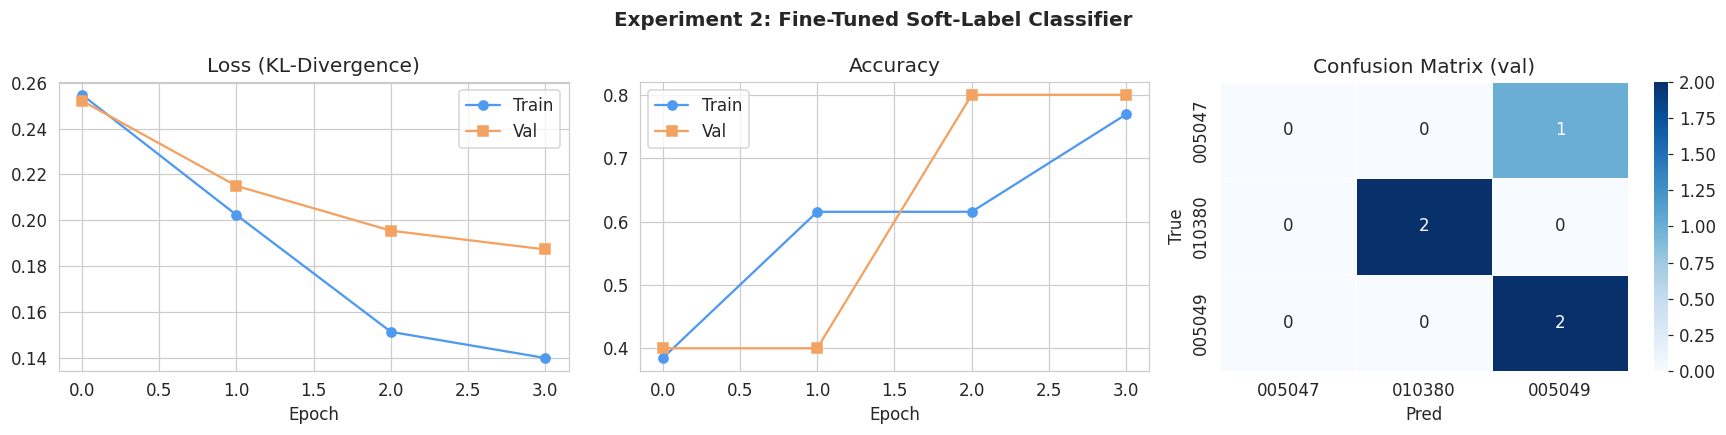


Classification Report:
              precision    recall  f1-score   support

      005047       0.00      0.00      0.00         1
      010380       1.00      1.00      1.00         2
      005049       0.67      1.00      0.80         2

    accuracy                           0.80         5
   macro avg       0.56      0.67      0.60         5
weighted avg       0.67      0.80      0.72         5



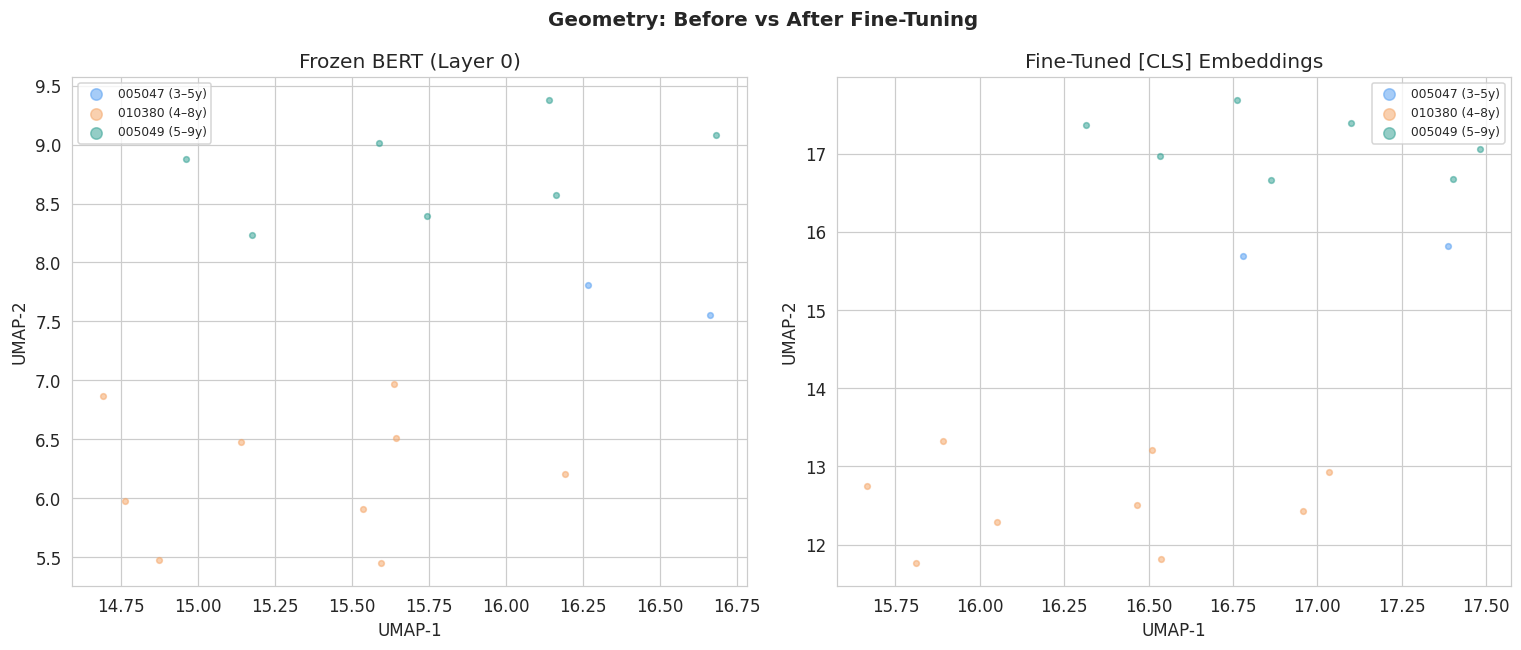

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, keys, title in zip(axes[:2],
    [('train_loss','val_loss'), ('train_acc','val_acc')],
    ['Loss (KL-Divergence)', 'Accuracy']):
    ax.plot(history[keys[0]], marker='o', label='Train', color='#4e9af1')
    ax.plot(history[keys[1]], marker='s', label='Val',   color='#f4a261')
    ax.set_xlabel('Epoch'); ax.set_title(title); ax.legend()

cm = confusion_matrix(vt, vp)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=story_ids_sorted, yticklabels=story_ids_sorted, linewidths=0.5)
axes[2].set_title('Confusion Matrix (val)'); axes[2].set_ylabel('True'); axes[2].set_xlabel('Pred')

plt.suptitle('Experiment 2: Fine-Tuned Soft-Label Classifier', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

print('\nClassification Report:')
print(classification_report(vt, vp, target_names=story_ids_sorted))

# UMAP before vs after
full_loader = DataLoader(StoryDataset(df, bert_tokenizer), batch_size=32)
_, _, _, ft_all_embs = run_epoch(ft_model, full_loader)

fig2, axes2 = plt.subplots(1, 2, figsize=(14, 6))
plot_umap_panel(axes2[0], layer_embs[best_layer], all_labels,
                f'Frozen BERT (Layer {best_layer})')
plot_umap_panel(axes2[1], ft_all_embs, all_labels,
                'Fine-Tuned [CLS] Embeddings')
plt.suptitle('Geometry: Before vs After Fine-Tuning', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

## Experiment 3 — Transfer Asymmetry

**Hypothesis:** If register is hierarchically nested (younger stories use simpler vocabulary that also appears in older stories, but not vice versa), then a model trained on *older* stories should generalise to *younger* ones better than the reverse.

We operationalise this as: $\Delta_{asym} = \text{Acc}_{old \to young} - \text{Acc}_{young \to old}$. A positive Δ is evidence for the nesting hypothesis.

In [ ]:
def transfer_experiment(train_ids, test_ids, label=''):
    tr_df = df[df['story_id'].isin(train_ids)]
    te_df = df[df['story_id'].isin(test_ids)]
    tr_l  = DataLoader(StoryDataset(tr_df, bert_tokenizer), batch_size=BATCH_SIZE, shuffle=True)
    te_l  = DataLoader(StoryDataset(te_df, bert_tokenizer), batch_size=BATCH_SIZE)
    m    = SoftLabelDistilBERT(n_classes).to(DEVICE)
    opt  = torch.optim.AdamW(m.parameters(), lr=LR, weight_decay=0.01)
    steps = len(tr_l) * FINETUNE_EPOCHS
    sched = get_linear_schedule_with_warmup(opt, steps//10, steps)
    for _ in range(FINETUNE_EPOCHS):
        run_epoch(m, tr_l, opt, sched)
    _, p, t, _ = run_epoch(m, te_l)
    acc = (p == t).mean()
    print(f'  {label:50s}  Acc={acc:.3f}')
    return acc

youngest, middle, oldest = story_ids_sorted
print('Running transfer experiments...')
acc_yo = transfer_experiment([youngest], [oldest],  f'{youngest}(young) → {oldest}(old)')
acc_oy = transfer_experiment([oldest],  [youngest], f'{oldest}(old)   → {youngest}(young)')
acc_mo = transfer_experiment([middle],  [oldest],   f'{middle}(mid)   → {oldest}(old)')
acc_my = transfer_experiment([middle],  [youngest], f'{middle}(mid)   → {youngest}(young)')
delta_asym = acc_oy - acc_yo
print(f'\nAsymmetry Δ = {acc_oy:.3f} − {acc_yo:.3f} = {delta_asym:+.3f}')

Running transfer experiments...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  005047(young) → 005049(old)                         Acc=0.000


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

...

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  010380(mid)   → 005049(old)                         Acc=0.714


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  010380(mid)   → 005047(young)                       Acc=0.000

Asymmetry Δ = 0.000 − 0.000 = +0.000


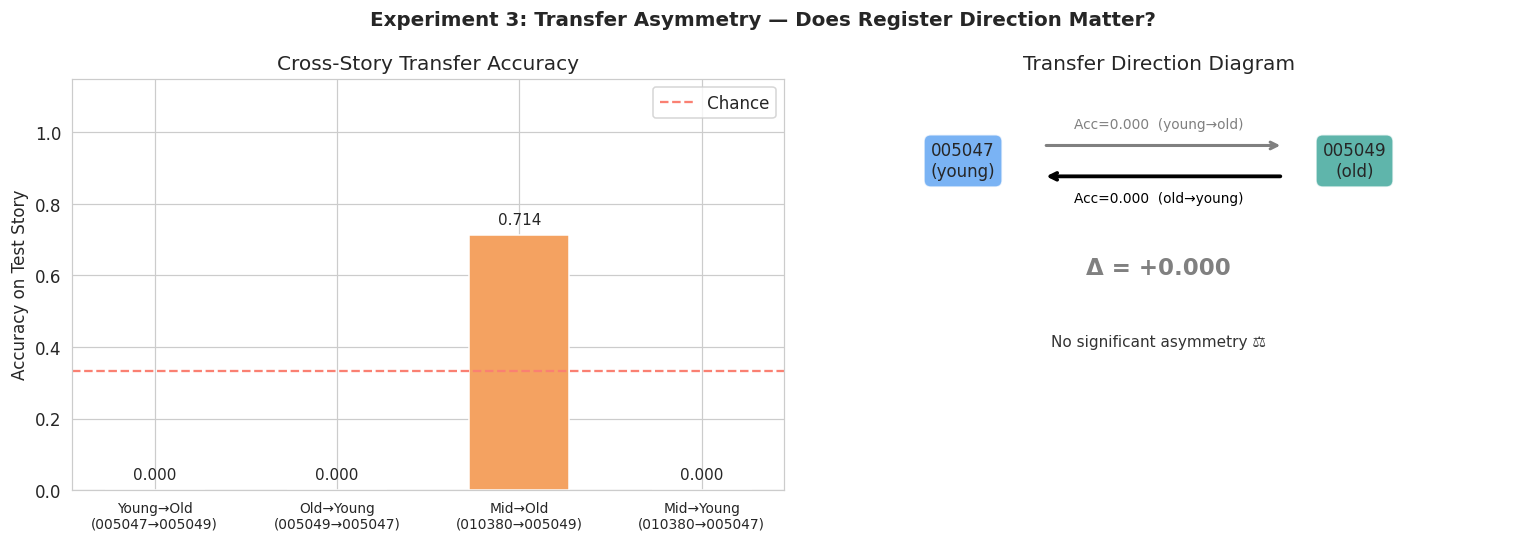

In [ ]:
accs_bar  = [acc_yo, acc_oy, acc_mo, acc_my]
bar_names = [f'Young→Old\n({youngest}→{oldest})',
             f'Old→Young\n({oldest}→{youngest})',
             f'Mid→Old\n({middle}→{oldest})',
             f'Mid→Young\n({middle}→{youngest})']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
ax = axes[0]
bar_colors = [PALETTE[0], PALETTE[2], PALETTE[1], PALETTE[1]]
bars = ax.bar(range(4), accs_bar, color=bar_colors, edgecolor='white', width=0.55)
ax.axhline(1/n_classes, color='salmon', ls='--', label='Chance')
ax.set_xticks(range(4)); ax.set_xticklabels(bar_names, fontsize=9)
ax.set_ylim(0, 1.15); ax.set_ylabel('Accuracy on Test Story')
ax.set_title('Cross-Story Transfer Accuracy'); ax.legend()
for bar, v in zip(bars, accs_bar):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.03, f'{v:.3f}', ha='center', fontsize=10)

# Asymmetry diagram
ax2 = axes[1]
ax2.set_xlim(0, 4); ax2.set_ylim(0, 4); ax2.axis('off')
ax2.text(0.9, 3.2, f'{youngest}\n(young)', ha='center', va='center',
         bbox=dict(boxstyle='round,pad=0.4', fc=PALETTE[0], alpha=0.75), fontsize=11)
ax2.text(3.1, 3.2, f'{oldest}\n(old)', ha='center', va='center',
         bbox=dict(boxstyle='round,pad=0.4', fc=PALETTE[2], alpha=0.75), fontsize=11)
# young->old arrow (grey = weaker)
ax2.annotate('', xy=(2.7, 3.35), xytext=(1.35, 3.35),
             arrowprops=dict(arrowstyle='->', lw=2, color='grey'))
ax2.text(2.0, 3.52, f'Acc={acc_yo:.3f}  (young→old)', ha='center', fontsize=9, color='grey')
# old->young arrow (bold = stronger)
ax2.annotate('', xy=(1.35, 3.05), xytext=(2.7, 3.05),
             arrowprops=dict(arrowstyle='->', lw=2.5, color='black'))
ax2.text(2.0, 2.80, f'Acc={acc_oy:.3f}  (old→young)', ha='center', fontsize=9, color='black')
col_d = PALETTE[2] if delta_asym > 0.05 else (PALETTE[0] if delta_asym < -0.05 else 'grey')
ax2.text(2.0, 2.1, f'Δ = {delta_asym:+.3f}', ha='center', fontsize=15, color=col_d, fontweight='bold')
interp = ('Old→Young transfers better\n→ supports register nesting ✅'
          if delta_asym > 0.05 else
          'Young→Old transfers better\n→ reverse hierarchy 🔄'
          if delta_asym < -0.05 else
          'No significant asymmetry ⚖️')
ax2.text(2.0, 1.4, interp, ha='center', fontsize=10, color='#333')
ax2.set_title('Transfer Direction Diagram')

plt.suptitle('Experiment 3: Transfer Asymmetry — Does Register Direction Matter?',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

## Experiment 4 — Activation Steering

**Rationale:** Probing and classification are *correlational*. Activation steering provides a **causal test**: we compute a mean-difference vector

$$v_\ell = \hat{\mu}^{old}_\ell \;-\; \hat{\mu}^{young}_\ell$$

using last-token activations from story chunks at each GPT-2 layer, then inject it into the residual stream during generation:

$$h_\ell \leftarrow h_\ell + \alpha \cdot \frac{v_\ell}{\|v_\ell\|}$$

If the steered model generates longer words and more varied vocabulary, the representation isn't just passively storing age register — it actively drives generation. We sweep both $\ell$ (layer) and $\alpha$ (strength), mirroring the approach in the reference notebook, and measure two proxy **register complexity** metrics:
- **Mean word length** (longer words → more complex vocabulary)
- **Type-Token Ratio** (TTR = unique/total words; higher → more diverse vocabulary)

In [ ]:
print(f'Loading {GPT2_MODEL}...')
gpt2_config    = AutoConfig.from_pretrained(GPT2_MODEL)
gpt2_model     = AutoModelForCausalLM.from_pretrained(GPT2_MODEL, config=gpt2_config)
gpt2_tokenizer = AutoTokenizer.from_pretrained(GPT2_MODEL)
gpt2_tokenizer.pad_token_id = gpt2_tokenizer.eos_token_id
gpt2_model.eval().to(DEVICE)
print(f'GPT-2: {gpt2_config.n_layer} transformer layers, hidden={gpt2_config.n_embd}')

Loading gpt2...


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

GPT-2: 12 transformer layers, hidden=768


In [ ]:
@torch.no_grad()
def get_mean_difference_vectors(model, tokenizer, pos_texts, neg_texts, prompt_prefix=''):
    """
    Compute normalised mean-difference steering vectors for each layer.
    Uses last-token activations (matching the reference notebook's approach).
    Returns tensor of shape (n_layers+1, hidden_size).

        v_l = norm(mu_pos_l) - norm(mu_neg_l)
    """
    def mean_last_token(texts):
        layer_acts = None
        for text in texts:
            inp = tokenizer(prompt_prefix + text, return_tensors='pt').to(model.device)
            out = model(**inp, output_hidden_states=True)
            for li, hs in enumerate(out.hidden_states):
                vec = hs[0, -1, :].detach()
                if layer_acts is None:
                    layer_acts = [[] for _ in range(len(out.hidden_states))]
                layer_acts[li].append(vec)
        return torch.stack([torch.stack(acts).mean(0) for acts in layer_acts])

    print(f'  mu_old   (n={len(pos_texts)})...')
    mu_pos = mean_last_token(pos_texts)
    print(f'  mu_young (n={len(neg_texts)})...')
    mu_neg = mean_last_token(neg_texts)

    diff = (mu_pos / mu_pos.norm(dim=-1, keepdim=True)
          - mu_neg / mu_neg.norm(dim=-1, keepdim=True))
    return diff / diff.norm(dim=-1, keepdim=True)   # (n_layers+1, hidden)

young_texts = df[df['story_id'] == youngest]['text'].sample(
    min(300, (df['story_id']==youngest).sum()), random_state=SEED).tolist()
old_texts   = df[df['story_id'] == oldest  ]['text'].sample(
    min(300, (df['story_id']==oldest  ).sum()), random_state=SEED).tolist()

print(f'Computing steering vectors: {len(old_texts)} old vs {len(young_texts)} young chunks')
steer_vecs = get_mean_difference_vectors(
    gpt2_model, gpt2_tokenizer,
    pos_texts=old_texts, neg_texts=young_texts,
    prompt_prefix='The story begins: '
)
print(f'Steering vectors shape: {steer_vecs.shape}')

Computing steering vectors: 7 old vs 2 young chunks
  mu_old   (n=7)...
  mu_young (n=2)...
Steering vectors shape: torch.Size([13, 768])


In [ ]:
def get_steering_hook(steering_vector, alpha, target_idx):
    """Forward hook: h[target_idx] += alpha * v."""
    def hook_fn(module, inputs, outputs):
        is_tuple = isinstance(outputs, tuple)
        hs = outputs[0] if is_tuple else outputs
        idx = hs.shape[1] + target_idx if target_idx < 0 else target_idx
        if 0 <= idx < hs.shape[1]:
            hs[:, idx, :] += alpha * steering_vector
        return (hs,) + outputs[1:] if is_tuple else hs
    return hook_fn

def generate_steered(model, tokenizer, steer_vecs, layer, alpha, prompt,
                     target_idx=-1, max_new=35, n_samples=3):
    """Generate with steering vector injected at `layer`. Hook is always removed."""
    vec = steer_vecs[layer]
    try:
        target_module = model.transformer.h[layer - 1]
    except (AttributeError, IndexError):
        target_module = model.model.layers[layer - 1]
    hook_h = target_module.register_forward_hook(
        get_steering_hook(vec, alpha, target_idx))
    outputs = []
    try:
        inp = tokenizer(prompt, return_tensors='pt').to(model.device)
        for _ in range(n_samples):
            with torch.no_grad():
                out = model.generate(**inp, max_new_tokens=max_new,
                                     temperature=0.9, do_sample=True,
                                     pad_token_id=tokenizer.eos_token_id)
            outputs.append(tokenizer.decode(out[0], skip_special_tokens=True))
    finally:
        hook_h.remove()  # critical: always remove hook
    return outputs

def register_complexity(texts):
    """Proxy metrics: mean word length, Type-Token Ratio, mean sentence length."""
    wl, ttrs, sl = [], [], []
    for t in texts:
        words = re.findall(r'[a-zA-Z]+', t)
        if not words: continue
        wl.append(np.mean([len(w) for w in words]))
        ttrs.append(len(set(w.lower() for w in words)) / len(words))
        sents = [s for s in re.split(r'[.!?]+', t) if s.strip()]
        sl.append(np.mean([len(s.split()) for s in sents]) if sents else 0)
    return {'mean_word_len': np.mean(wl) if wl else 0,
            'ttr': np.mean(ttrs)          if ttrs else 0,
            'mean_sent_len': np.mean(sl)  if sl else 0}

print('Hook system ready.')

Hook system ready.


In [ ]:
STEER_PROMPT = 'Once upon a time, the child'
target_tok   = len(gpt2_tokenizer.encode(STEER_PROMPT)) - 1
N_LAYERS     = steer_vecs.shape[0] - 1

# ── Baseline ──────────────────────────────────────────────────────────────────
baseline_outs = generate_steered(gpt2_model, gpt2_tokenizer, steer_vecs,
                                  1, 0, STEER_PROMPT, target_tok, max_new=35, n_samples=5)
baseline = register_complexity(baseline_outs)
print('Baseline (alpha=0):', {k: f'{v:.3f}' for k, v in baseline.items()})

# ── Layer sweep at fixed alpha ────────────────────────────────────────────────
alpha_fixed  = 60
layer_metrics = {}
print(f'\nLayer sweep (alpha={alpha_fixed})...')
for li in range(1, N_LAYERS + 1):
    outs = generate_steered(gpt2_model, gpt2_tokenizer, steer_vecs,
                            li, alpha_fixed, STEER_PROMPT, target_tok, max_new=35, n_samples=4)
    layer_metrics[li] = register_complexity(outs)

# ── Alpha sweep at best layer ─────────────────────────────────────────────────
best_steer_layer = max(1, min(best_layer, N_LAYERS))
alpha_values  = [0, 20, 40, 60, 80, 100, 120]
alpha_metrics = {}
print(f'Alpha sweep (layer={best_steer_layer})...')
for alpha in alpha_values:
    outs = generate_steered(gpt2_model, gpt2_tokenizer, steer_vecs,
                            best_steer_layer, alpha, STEER_PROMPT, target_tok, max_new=35, n_samples=4)
    alpha_metrics[alpha] = register_complexity(outs)
    print(f'  alpha={alpha:4d}  word_len={alpha_metrics[alpha]["mean_word_len"]:.3f}  '
          f'TTR={alpha_metrics[alpha]["ttr"]:.3f}  sent_len={alpha_metrics[alpha]["mean_sent_len"]:.1f}')

Baseline (alpha=0): {'mean_word_len': '3.900', 'ttr': '0.856', 'mean_sent_len': '13.667'}

Layer sweep (alpha=60)...
Alpha sweep (layer=1)...
  alpha=   0  word_len=3.422  TTR=0.690  sent_len=24.9
  alpha=  20  word_len=3.840  TTR=0.763  sent_len=15.1
  alpha=  40  word_len=3.704  TTR=0.759  sent_len=18.6
  alpha=  60  word_len=3.745  TTR=0.801  sent_len=14.2
  alpha=  80  word_len=3.772  TTR=0.715  sent_len=15.0
  alpha= 100  word_len=3.747  TTR=0.796  sent_len=16.7
  alpha= 120  word_len=3.749  TTR=0.814  sent_len=10.0


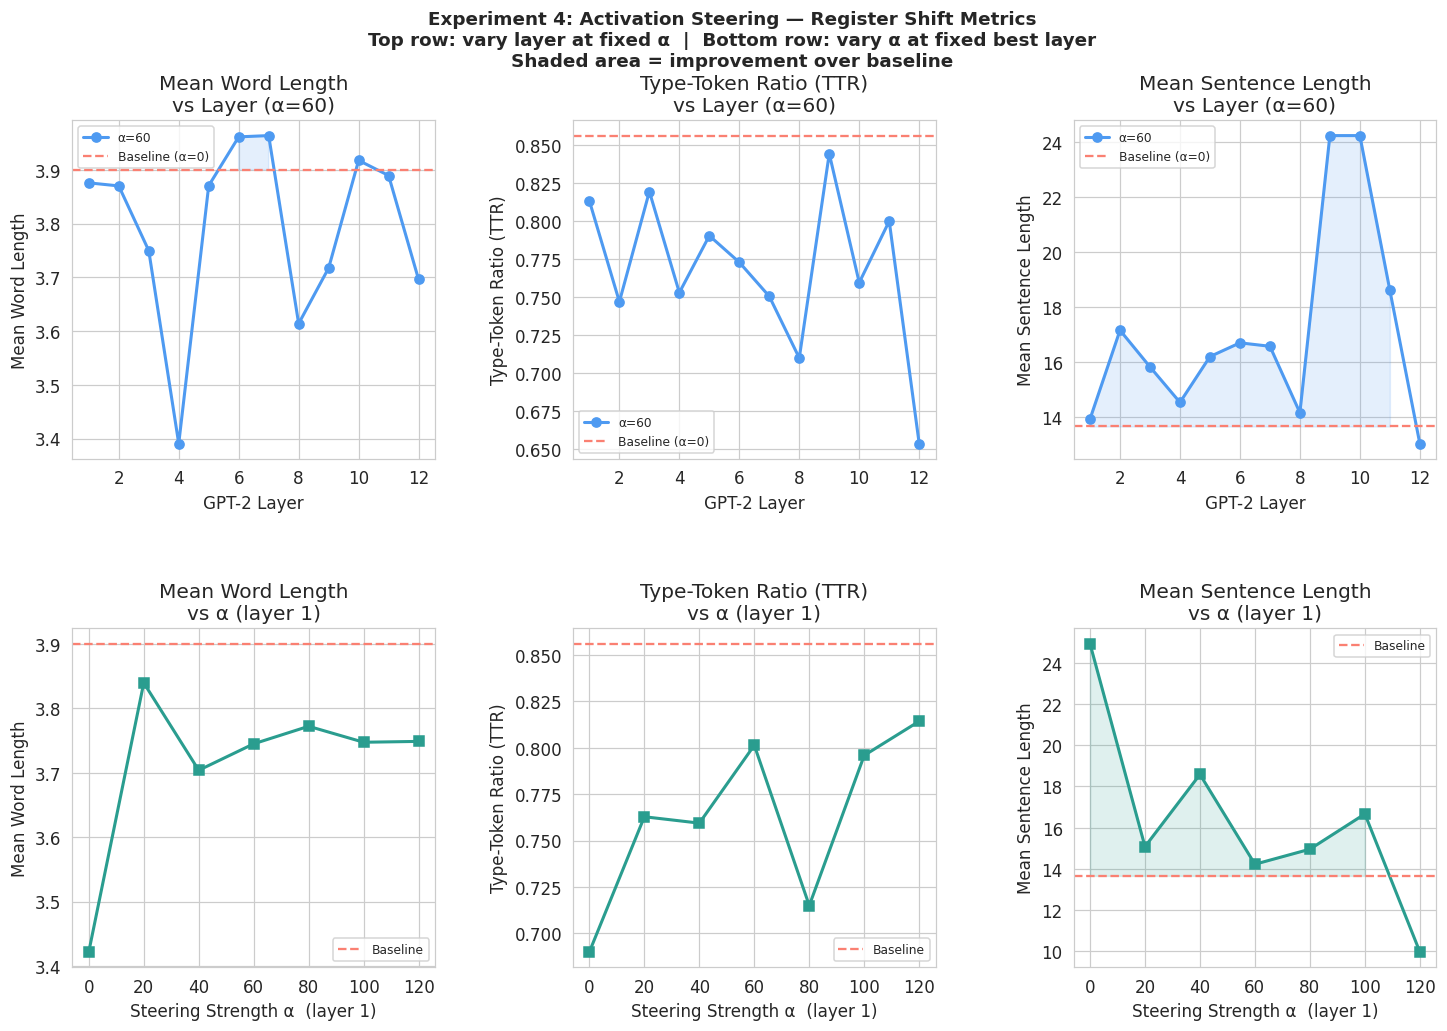

In [ ]:
layers     = sorted(layer_metrics.keys())
metrics    = ['mean_word_len', 'ttr', 'mean_sent_len']
metric_lab = ['Mean Word Length', 'Type-Token Ratio (TTR)', 'Mean Sentence Length']

fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.50, wspace=0.38)

# Row 0: layer sweep
for ci, (mk, ml) in enumerate(zip(metrics, metric_lab)):
    ax = fig.add_subplot(gs[0, ci])
    vals = [layer_metrics[l][mk] for l in layers]
    ax.plot(layers, vals, marker='o', color='#4e9af1', lw=2, label=f'α={alpha_fixed}')
    ax.axhline(baseline[mk], color='salmon', ls='--', label='Baseline (α=0)')
    ax.fill_between(layers, vals, baseline[mk],
                    where=[v > baseline[mk] for v in vals],
                    alpha=0.15, color='#4e9af1')
    ax.set_xlabel('GPT-2 Layer'); ax.set_ylabel(ml)
    ax.set_title(f'{ml}\nvs Layer (α={alpha_fixed})')
    ax.legend(fontsize=8)

# Row 1: alpha sweep
for ci, (mk, ml) in enumerate(zip(metrics, metric_lab)):
    ax = fig.add_subplot(gs[1, ci])
    vals_a = [alpha_metrics[a][mk] for a in alpha_values]
    ax.plot(alpha_values, vals_a, marker='s', color='#2a9d8f', lw=2)
    ax.axhline(baseline[mk], color='salmon', ls='--', label='Baseline')
    ax.fill_between(alpha_values, vals_a, baseline[mk],
                    where=[v > baseline[mk] for v in vals_a],
                    alpha=0.15, color='#2a9d8f')
    ax.set_xlabel(f'Steering Strength α  (layer {best_steer_layer})')
    ax.set_ylabel(ml)
    ax.set_title(f'{ml}\nvs α (layer {best_steer_layer})')
    ax.legend(fontsize=8)

plt.suptitle(
    'Experiment 4: Activation Steering — Register Shift Metrics\n'
    'Top row: vary layer at fixed α  |  Bottom row: vary α at fixed best layer\n'
    'Shaded area = improvement over baseline',
    fontsize=12, fontweight='bold')
plt.savefig('steering_results.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
# ── Qualitative outputs ───────────────────────────────────────────────────────
print('=' * 72)
print(f'QUALITATIVE OUTPUTS  |  Prompt: "{STEER_PROMPT}"')
print('=' * 72)
print('\n[No steering]')
for o in baseline_outs[:2]: print(f'  {o}')

for a in [40, 80, 120]:
    outs_show = generate_steered(gpt2_model, gpt2_tokenizer, steer_vecs,
                                  best_steer_layer, a, STEER_PROMPT,
                                  target_tok, max_new=35, n_samples=2)
    print(f'\n[Layer {best_steer_layer}, α={a} → older register]')
    for o in outs_show: print(f'  {o}')

QUALITATIVE OUTPUTS  |  Prompt: "Once upon a time, the child"

[No steering]
  Once upon a time, the child would be allowed to make his own arrangements for his life, but there were times when this rule made a little bit of sense. One boy, for example, became so anxious
  Once upon a time, the child's father and mother were together, but she wouldn't accept anything from him. It seemed that she was doing her duty without the mother.

As it turned out,

[Layer 1, α=40 → older register]
  Once upon a time, the child-rearing population of the world could have been reduced to a mere tenth-of-a-million-tonne. And, though the world was already living up to
  Once upon a time, the child came in my room with his head bowed down, his whole body shaking. He looked up at me and said, "Father, I hear you're sick. If you tell

[Layer 1, α=80 → older register]
  Once upon a time, the child had been born, and the king was an angel. They did not know what they were supposed to do, but they felt God, a

## Final Summary Dashboard

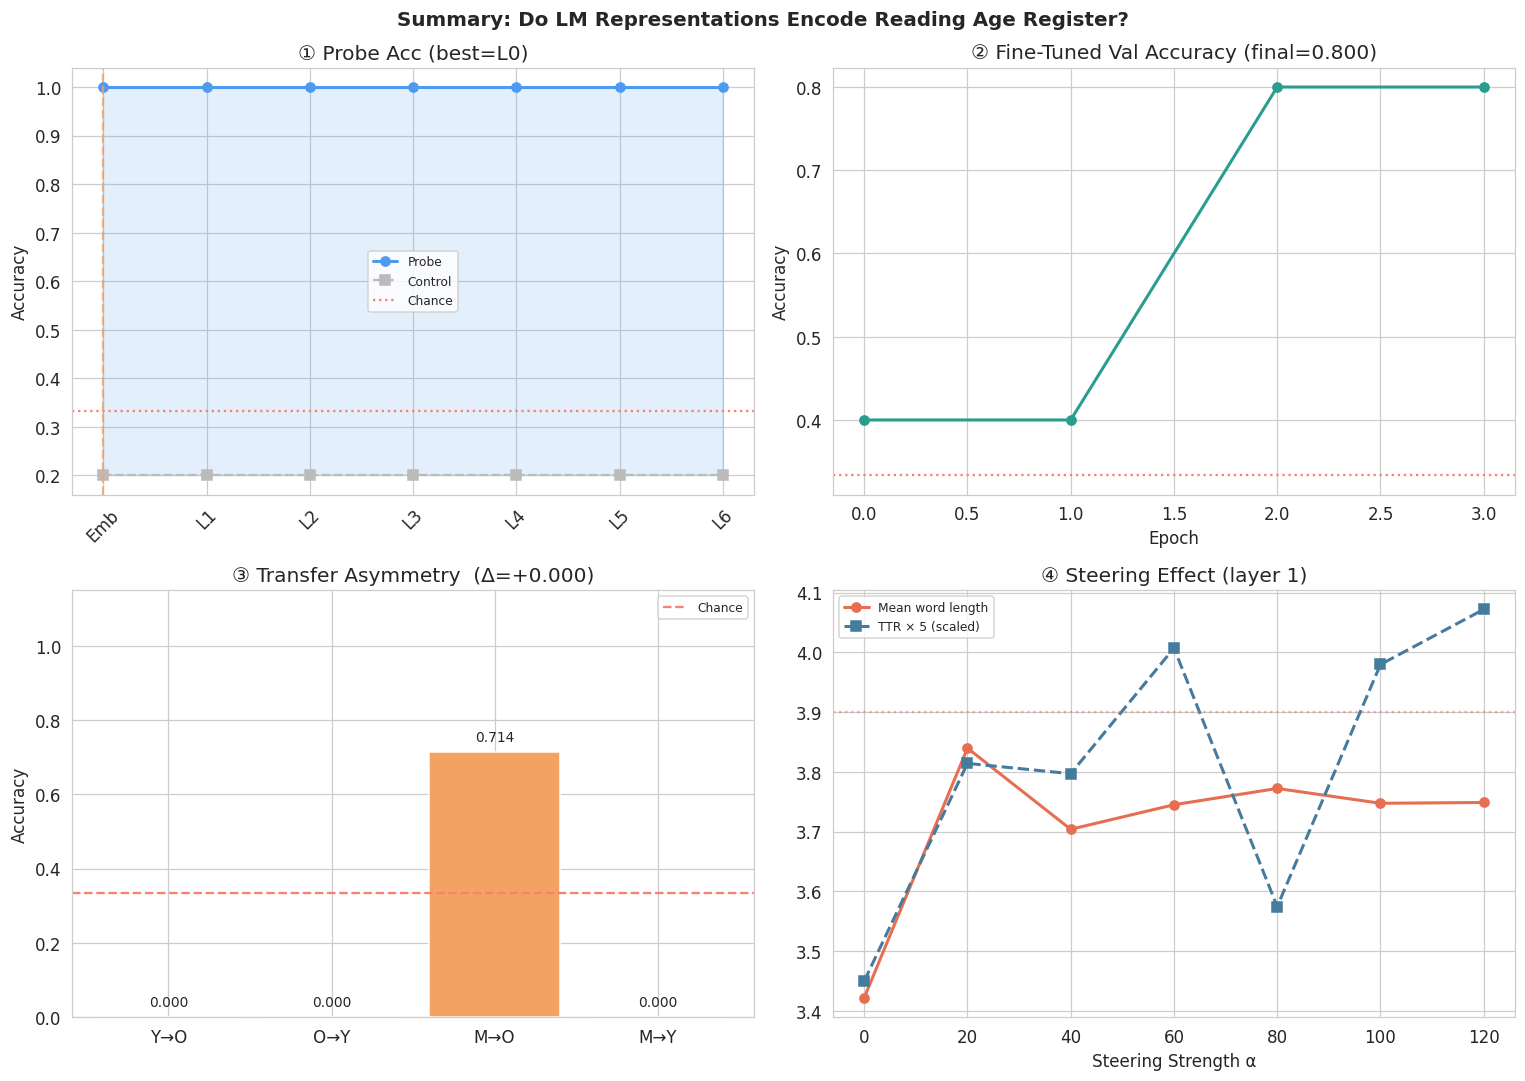


RESULTS SUMMARY
① Best probe layer   : L0  (acc=1.000, Δover_control=+0.800)
② Fine-tuned val acc : 0.800
③ Transfer asym Δ    : +0.000  No significant asymmetry ⚖️
④ Steering peak α    : 20  (word-length gain=-0.061 ⚠️ try higher α or more data)


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Layer probe
ax = axes[0, 0]
ax.plot(probe_accs,    marker='o', color='#4e9af1', lw=2, label='Probe')
ax.plot(control_accs, marker='s', color='#bbb', lw=1.5, ls='--', label='Control')
ax.axhline(1/n_classes, color='salmon', ls=':', label='Chance')
ax.axvline(best_layer, color='#f4a261', ls='--', alpha=0.8)
ax.fill_between(range(len(probe_accs)), probe_accs, control_accs, alpha=0.15, color='#4e9af1')
ax.set_xticks(range(len(probe_accs)))
ax.set_xticklabels(['Emb']+[f'L{i}' for i in range(1,len(probe_accs))], rotation=45)
ax.set_title(f'① Probe Acc (best=L{best_layer})')
ax.set_ylabel('Accuracy'); ax.legend(fontsize=8)

# 2. Fine-tuned val accuracy
ax2 = axes[0, 1]
ax2.plot(history['val_acc'], marker='o', color='#2a9d8f', lw=2)
ax2.axhline(1/n_classes, color='salmon', ls=':')
ax2.set_title(f'② Fine-Tuned Val Accuracy (final={history["val_acc"][-1]:.3f})')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy')

# 3. Transfer asymmetry
ax3 = axes[1, 0]
bar_cols = [PALETTE[0], PALETTE[2], PALETTE[1], PALETTE[1]]
bars = ax3.bar(['Y→O','O→Y','M→O','M→Y'], accs_bar, color=bar_cols, edgecolor='white')
ax3.axhline(1/n_classes, color='salmon', ls='--', label='Chance')
ax3.set_ylim(0, 1.15); ax3.set_ylabel('Accuracy')
ax3.set_title(f'③ Transfer Asymmetry  (Δ={delta_asym:+.3f})')
for bar, v in zip(bars, accs_bar):
    ax3.text(bar.get_x()+bar.get_width()/2, v+0.03, f'{v:.3f}', ha='center', fontsize=9)
ax3.legend(fontsize=8)

# 4. Steering (alpha sweep, word length)
ax4 = axes[1, 1]
ax4.plot(alpha_values, [alpha_metrics[a]['mean_word_len'] for a in alpha_values],
         marker='o', color='#e76f51', lw=2, label='Mean word length')
ax4.plot(alpha_values, [alpha_metrics[a]['ttr']*5 for a in alpha_values],
         marker='s', color='#457b9d', lw=2, ls='--', label='TTR × 5 (scaled)')
ax4.axhline(baseline['mean_word_len'], color='#e76f51', ls=':', alpha=0.5)
ax4.set_xlabel('Steering Strength α')
ax4.set_title(f'④ Steering Effect (layer {best_steer_layer})')
ax4.legend(fontsize=8)

plt.suptitle('Summary: Do LM Representations Encode Reading Age Register?',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('summary_dashboard.png', dpi=120, bbox_inches='tight')
plt.show()

# ── Print summary ─────────────────────────────────────────────────────────────
best_alpha_wl = alpha_values[int(np.argmax([alpha_metrics[a]['mean_word_len'] for a in alpha_values]))]
wl_gain = alpha_metrics[best_alpha_wl]['mean_word_len'] - baseline['mean_word_len']

print('\n' + '='*70)
print('RESULTS SUMMARY')
print('='*70)
print(f'① Best probe layer   : L{best_layer}  '
      f'(acc={probe_accs[best_layer]:.3f}, Δover_control={probe_accs[best_layer]-control_accs[best_layer]:+.3f})')
print(f'② Fine-tuned val acc : {history["val_acc"][-1]:.3f}')
print(f'③ Transfer asym Δ    : {delta_asym:+.3f}  '
      + ('Old→Young transfers better → register nesting ✅' if delta_asym > 0.05
         else 'Young→Old transfers better 🔄' if delta_asym < -0.05
         else 'No significant asymmetry ⚖️'))
print(f'④ Steering peak α    : {best_alpha_wl}  '
      f'(word-length gain={wl_gain:+.3f} '
      + ('✅' if wl_gain > 0.1 else '⚠️ try higher α or more data') + ')')